In [1]:
print('theme')

theme


In [2]:
import pandas as pd
pd.set_option('display.max_columns', None)
import matplotlib.pyplot as plt
import seaborn as sns
custom_pal = sns.color_palette(['#ff5858', '#fcc642', '#dba0db', '#72d9f0', '#a5cf27'])

import sqlite3

# encoding libraries
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# preprocessing
from sklearn.model_selection import train_test_split

#models
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.model_selection import GridSearchCV

# metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, classification_report
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

#### Load data from sql

In [3]:
conn = sqlite3.connect('small_tables.db')
query = 'SELECT * FROM const_new_2'
constnew_df = pd.read_sql_query(query, conn)
conn.close()

#### Common Functions

In [4]:
# fuction to cast data
''' data cast
        inputs: column name
                data type
                placeholder: Value to fill if the specific val is empty
        returns: new dataframe
        '''
def data_cast(df, column_name, data_type = str, placeholder = 'None'):
    df[column_name] = df[column_name].fillna(placeholder)
    df[column_name] = df[column_name].astype(data_type)
    
    return df

In [5]:
# function to make a new results dataframe from a model
''' make_results_df
        inputs: X_test: Testing dataset
                X_train: Trainign dataset
                master_df : master dataframe with all data
                results_column_name : name of the new results column to be created
                contact_id : name of the column containing contact id
                train_pred : train predictions data
                test_pred : testing predictions data
        returns: new dataframe with updates probailities and contact id
        '''
    
def make_results_df(X_train, X_test, master_df, results_column_name, contact_id, train_pred, test_pred):
    train_result_df = X_train.copy()
    train_result_df[contact_id] = master_df.loc[X_train.index, contact_id]
    train_result_df[results_column_name] = train_pred * 100
    
    test_result_df = X_test.copy()
    test_result_df[contact_id] = master_df.loc[X_test.index, contact_id]
    test_result_df[results_column_name] = test_pred * 100

    combined_df = pd.concat([train_result_df, test_result_df], axis = 0)
    sorted_df = combined_df.sort_index(ascending = True)
    col_c = sorted_df.pop(contact_id)
    sorted_df.insert(0, contact_id, col_c)
    
    return sorted_df

Regression Metrics:
1. Mean Absolute Error: Measures the average absolute difference between actual and predicted values. Lower value indicates better model performance.
2. Mean Squared Error: Measures the average sqaured difference between actual and predicted values. Penalizes larger errors more than smaller ones.
3. R-squared Score: Measures the proportion of the variance in the dependent variable that is predictable form the independent variable. Higher the value, better the model performance.

In [6]:
# Regression Metrics
def regression_metrics(y_test, y_pred):
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print('Mean Absolute Error: ', mae)
    print('Mean Squared Error: ', mse)
    print('R-sqaured Score: ', r2)
    

Classification Metrics:
1. Confusion Matrix: Summary of preiction results.
2. Accuracy: Meausres the proportion of correctly predicted instances out of the total instances.
3. Precision: Measure the proportion of true positives out of the total predicted positives.
4. Recall: Measures proportion of true positives out of the actual positives.
5. F1 Score: The harmonic mean of precision and recall, providing a metric that balances both.

In [7]:
# Classification Metrics
def classification_metrics(y_test, y_pred):
    cm = confusion_matrix(y_test, y_pred)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print('Confusion Matrix: \n')
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot = True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()
    
    print('Acuracy Score: ', accuracy)
    print('Precision: ', precision)
    print('Recall Score: ', recall)
    print('F1 Score: ', f1)

#### Drop deceased individuals data

In [8]:
# make a copy of the original data
mask_df = constnew_df.copy()

# drop living flag = no
mask_df.drop(mask_df[mask_df['LIVING_FLAG'] == 'N'].index, inplace = True)

#### Encoding for String Parameters

Column Transformer: Uses different signals for different features and puts them together.

    One-Hot Encoding: For categorical data
    Number Encoding: For numerical data

In [9]:
columns_to_encode = ['PRIMARY_CONSTITUENT_TYPE', 'EMPLOYMENT_STATUS']

# transform columns using one-hot encoder
ct = ColumnTransformer([('one_hot_encoder', OneHotEncoder(), columns_to_encode)], remainder = 'passthrough')

# make a new dataframe from the transformed data
encoded_df = pd.DataFrame(ct.fit_transform(mask_df), columns = ct.get_feature_names_out())

In [10]:
# drop if they have no employment status data
encoded_df = encoded_df.drop(['one_hot_encoder__EMPLOYMENT_STATUS_None'], axis = 1)

# edit column names
new_column_names = ['ALUMNI', 'ALUMNUS_PARTNER', 'CERTIFICATE_ALUMNI', 'CONTACT', 'CURRENT_PARENT', 'CURRENT_STUDENT', 'FACULTY_STAFF_PARTNER', 
                    'FACULTY_STAFF', 'FRIEND', 'NON_DEGREE', 'PAST_PARENT', 'CURRENT_EMPLOYEE', 'FORMER_EMPLOYEE', 'RETIRED','CONTACT_ID', 
                    'HOUSEHOLD_ID', 'PRIMARY_CONSTITUENT_FLAG', 'LIVING_FLAG', 'CONTACTABLE_FLAG', 'ANONYMOUS_FLAG', 'KNOWTIFY_FLAG', 
                    'AGE', 'ACQUISITION_AGE', 'MSU_RECEIVED', 'CITIZENSHIP', 'CERTIFICATE', 'BACHELORS', 'MASTERS', 'PROFESSIONAL', 'DOCTORATE',
                    'HONORS_COLLEGE', 'PREF_ZIPCODE', 'SCHOLARSHIP_RECIPIENT', 'EVENTS_ATTENDED', 'STUDENT_CLUBS', 'GREEK_LIFE', 'AWARD_RECIPIENT', 
                    'MSU_BOARD_OF_TRUSTEES']

encoded_df.columns = new_column_names

#### Cast data into their datatypes

In [11]:
# select only the state code and drop the local code
encoded_df['PREF_ZIPCODE'] = encoded_df['PREF_ZIPCODE'].apply(lambda val: val[:5] if pd.notna(val) else '0')

In [12]:
# Columns that need to be converted into strings
columns_str = ['PRIMARY_CONSTITUENT_FLAG', 'LIVING_FLAG', 'CONTACTABLE_FLAG', 'ANONYMOUS_FLAG', 'KNOWTIFY_FLAG', 'CERTIFICATE', 
           'BACHELORS', 'MASTERS', 'PROFESSIONAL', 'DOCTORATE', 'HONORS_COLLEGE', 'SCHOLARSHIP_RECIPIENT', 'STUDENT_CLUBS', 
           'GREEK_LIFE', 'AWARD_RECIPIENT', 'MSU_BOARD_OF_TRUSTEES', 'CITIZENSHIP']

# Columns that need to be converted into numbers
columns_num = ['AGE', 'ACQUISITION_AGE', 'MSU_RECEIVED', 'EVENTS_ATTENDED', 'ALUMNI', 'ALUMNUS_PARTNER', 'CERTIFICATE_ALUMNI', 
               'CONTACT', 'CURRENT_PARENT', 'CURRENT_STUDENT', 'FACULTY_STAFF_PARTNER', 'FACULTY_STAFF', 'FRIEND', 'NON_DEGREE', 
               'PAST_PARENT', 'CURRENT_EMPLOYEE', 'FORMER_EMPLOYEE', 'RETIRED']

for col in columns_str:
    data_cast(encoded_df, col)

for col in columns_num:
    data_cast(encoded_df, col, float, 0)

#### ENCODING FOR Y/N VALUES

In [13]:
# strings to their values
mapping = {'None': 0, 'Y': 1, 'N': 0, 'NaN': 0}

# columns to encoded
columns = ['PRIMARY_CONSTITUENT_FLAG', 'LIVING_FLAG', 'CONTACTABLE_FLAG', 'ANONYMOUS_FLAG', 'KNOWTIFY_FLAG', 'CERTIFICATE', 
           'BACHELORS', 'MASTERS', 'PROFESSIONAL', 'DOCTORATE', 'HONORS_COLLEGE', 'SCHOLARSHIP_RECIPIENT', 'STUDENT_CLUBS', 
           'GREEK_LIFE', 'AWARD_RECIPIENT', 'MSU_BOARD_OF_TRUSTEES']

for col in columns:
    encoded_df[col] = encoded_df[col].replace(mapping)

#### Dropping columns

In [14]:
# 1 if given gift, else 0
encoded_df['GIFT'] = encoded_df['MSU_RECEIVED'].apply(lambda x: 1 if x else 0)

encoded_df = encoded_df.drop(['CITIZENSHIP', 'HOUSEHOLD_ID', 'PREF_ZIPCODE'], axis = 1)

# drop amount
encoded_df = encoded_df.drop(['MSU_RECEIVED'], axis = 1)

#### EDA Data

##### Age Distribution Pie Chart

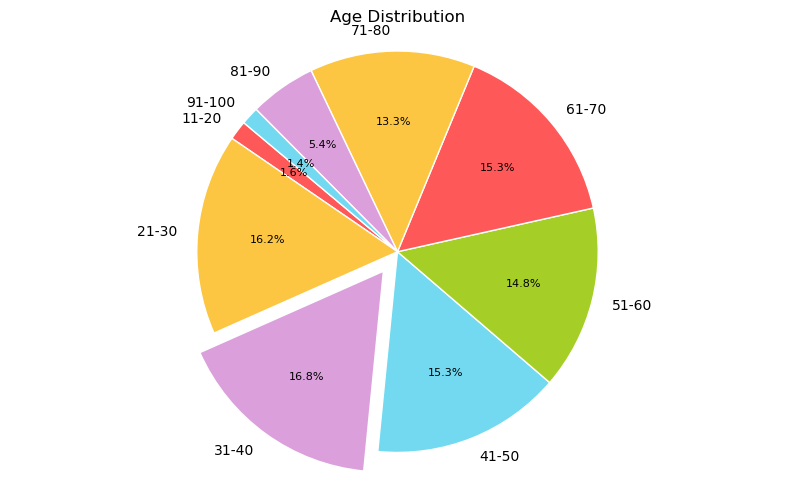

In [15]:
bins = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
labels = ['11-20', '21-30', '31-40', '41-50', '51-60', '61-70', '71-80', '81-90', '91-100']

non_zero_ages = encoded_df[encoded_df['AGE'] > 0]
age_groups = pd.cut(non_zero_ages['AGE'], bins = bins, labels = labels, right = False)
age_group_counts = age_groups.value_counts().sort_index()
age_group_counts = age_group_counts[age_group_counts > 0]

nonage_fig = plt.figure(figsize = (10, 6))


#plt.pie(age_group_counts, labels = age_group_counts.index, autopct = '%1.1f%%', startangle = 140)
wedges, texts, autotexts = plt.pie(
    age_group_counts,
    labels = age_group_counts.index,
    autopct = '%1.1f%%', 
    startangle = 140,
    wedgeprops = dict(edgecolor = 'white'),
    pctdistance = 0.65,
    labeldistance = 1.1,
    explode=[0, 0, 0.12, 0, 0, 0, 0, 0, 0],
    colors = custom_pal
)
for i, patch in enumerate(wedges):
  texts[i].set_color('black')
    
for text in autotexts:
    text.set_color('black')
    text.set_fontsize(8)
plt.title('Age Distribution', color='black')
plt.axis('equal')
plt.show()

#### Acquisition Age Distribution Pie Chart

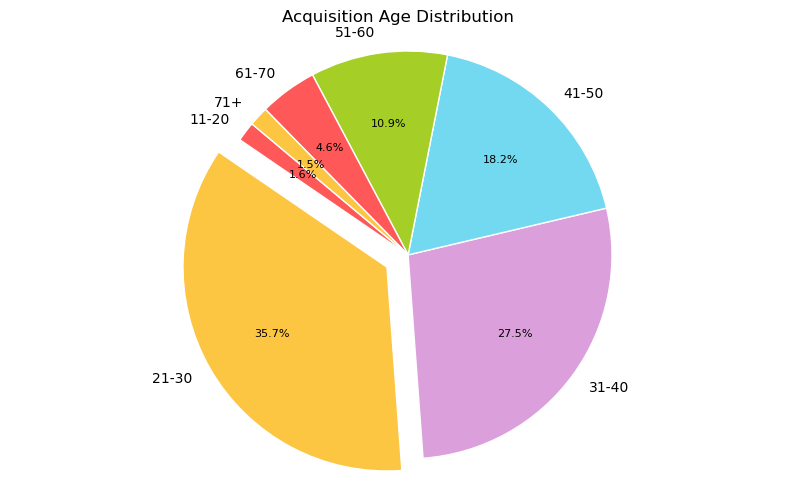

In [16]:
bins = [10, 20, 30, 40, 50, 60, 70, 80]
labels = ['11-20', '21-30', '31-40', '41-50', '51-60', '61-70', '71+']

non_zero_ages_acq = encoded_df[encoded_df['ACQUISITION_AGE'] > 0]
age_groups_acq = pd.cut(non_zero_ages_acq['ACQUISITION_AGE'], bins = bins, labels = labels, right = False)
age_group_counts_acq = age_groups_acq.value_counts().sort_index()
age_group_counts_acq = age_group_counts_acq[age_group_counts_acq > 0]

nonacq_fig = plt.figure(figsize = (10, 6))
#plt.pie(age_group_counts_acq, labels = age_group_counts_acq.index, autopct = '%1.1f%%', startangle = 140, edgecolor = )
wedges, texts, autotexts = plt.pie(
    age_group_counts_acq,
    labels = age_group_counts_acq.index,
    autopct = '%1.1f%%', 
    startangle = 140,
    wedgeprops = dict(edgecolor = 'white'),
    pctdistance = 0.65,
    labeldistance = 1.1,
    explode=[0, 0.12, 0, 0, 0, 0, 0],
    colors = custom_pal
)
for i, patch in enumerate(wedges):
  texts[i].set_color('black')
    
for text in autotexts:
    text.set_color('black')
    text.set_fontsize(8)
    
plt.title('Acquisition Age Distribution', color='black')
plt.axis('equal')
plt.show()

#### Spider Chart

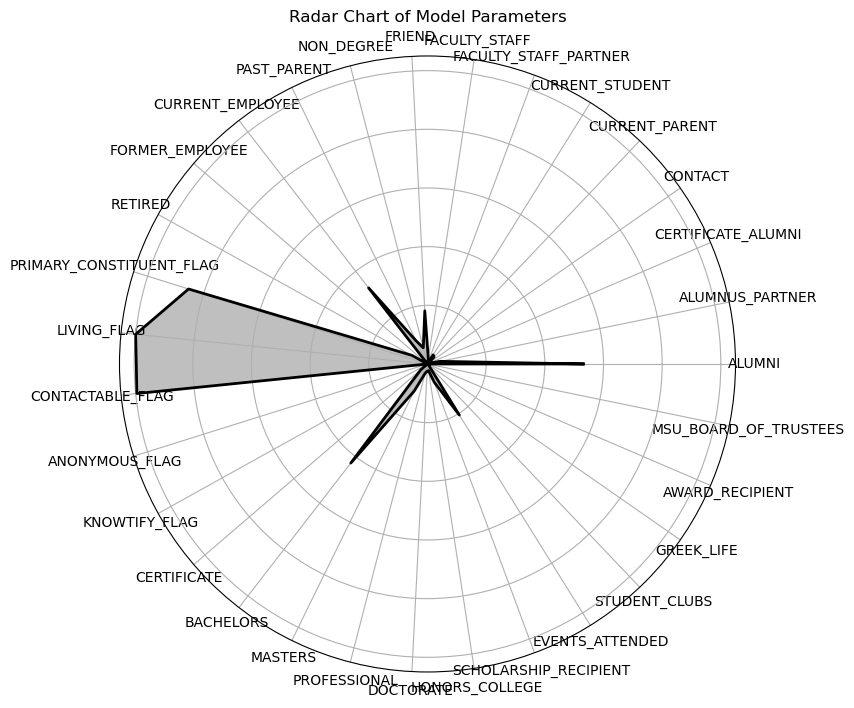

In [17]:
import numpy as np

spider_df = encoded_df.drop(['CONTACT_ID', 'AGE', 'ACQUISITION_AGE', 'GIFT'], axis = 1)
mean_data = spider_df.mean()

num_vars = len(spider_df.columns)

angles = np.linspace(0, 2*np.pi, num_vars, endpoint = False).tolist()
angles+= angles[:1]

values = mean_data.tolist()
values += values[:1]

fig, ax = plt.subplots(figsize=(8,8), subplot_kw = dict(polar=True))
ax.fill(angles, values, alpha = 0.25, color = 'black')
ax.plot(angles, values, linewidth=2, color = 'black')
ax.set_yticklabels([], color = 'white')
ax.set_xticks(angles[:-1])
ax.set_xticklabels(spider_df.columns, color = 'black')
plt.title('Radar Chart of Model Parameters', color = 'black')
plt.show()

fig.savefig('spider_fig.png', transparent=True)

#### Training and Testing Sets

These dataframes are commonly used across all models

In [18]:
# Drop gift and contact id
X = encoded_df.drop(['GIFT', 'CONTACT_ID'], axis = 1)  # features
y = encoded_df['GIFT']  # target variable

#splitting data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 450)

### Models - Acquisition Age

### Random Forest Regression

In [19]:
# rfr - random forest resgressor
model_rfr = RandomForestRegressor(n_estimators=100, random_state=42)
model_rfr.fit(X_train, y_train)

# predicted probability values
train_predictions_rfr = model_rfr.predict(X_train)
test_predictions_rfr = model_rfr.predict(X_test)

rfr_giving_df = make_results_df(X_train, X_test, encoded_df, 'GIVING_PROBABILITY', 'CONTACT_ID', train_predictions_rfr, test_predictions_rfr)

In [20]:
regression_metrics(y_test, test_predictions_rfr)

Mean Absolute Error:  0.11226587875038085
Mean Squared Error:  0.05693144012998186
R-sqaured Score:  0.7703228053301365


#### Random Forest Classifier

In [21]:
# rfc - random forest classifier
model_rfc = RandomForestClassifier(n_estimators = 1000)
model_rfc.fit(X_train, y_train)

# predicted probability values
train_predictions_rfc = model_rfc.predict(X_train)
test_predictions_rfc = model_rfc.predict(X_test)

rfc_giving_df = make_results_df(X_train, X_test, encoded_df, 'GIVING_PROBABILITY', 'CONTACT_ID', train_predictions_rfc, test_predictions_rfc)

Confusion Matrix: 



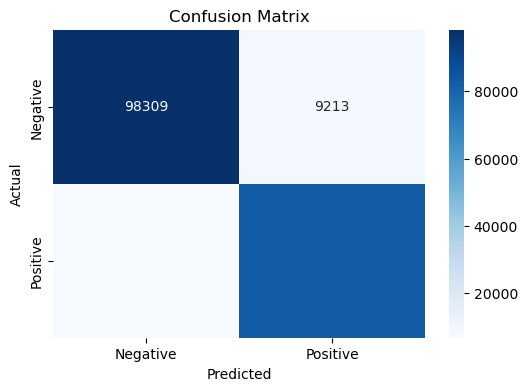

Acuracy Score:  0.9190075928794535
Precision:  0.89969733919784
Recall Score:  0.9246528593646851
F1 Score:  0.9120044144019865


In [22]:
classification_metrics(y_test, test_predictions_rfc)

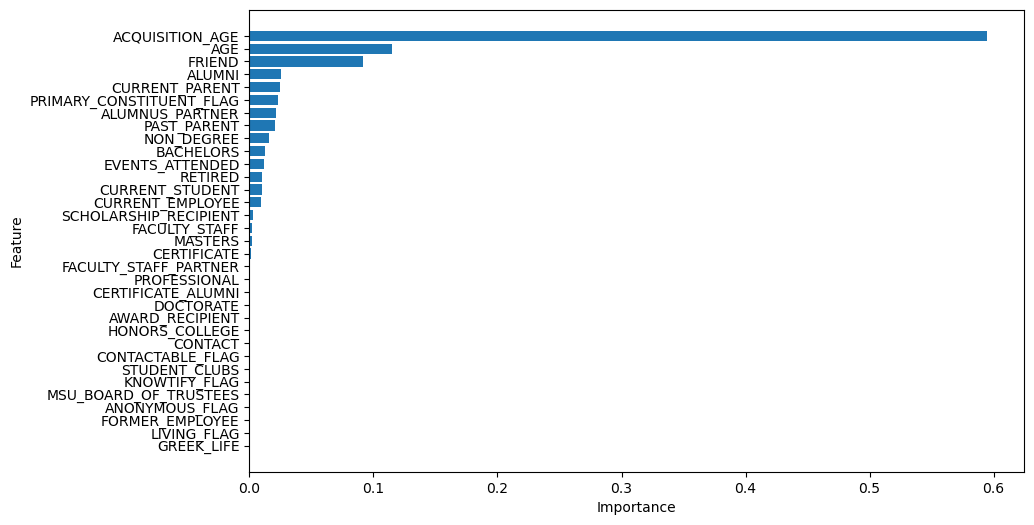

In [23]:
# feature importance
importance_rfc = model_rfc.feature_importances_

feature_imp_rfc = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': importance_rfc
    })
feature_imp_rfc = feature_imp_rfc.sort_values(by = 'Importance', ascending=False)
#print(feature_imp)

plt.figure(figsize=(10,6))
plt.barh(feature_imp_rfc['Feature'], feature_imp_rfc['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.gca().invert_yaxis()
plt.show()

#### XGBoost

1. XGBoost: Fore low-level APIs for training models and making predictions.
2. XGBClassifier: High-level API specifically designed for classification problems. (Wraps around XGBoost along with scikit learn)
3. XGBRegressor: High-level API for regression problems.

In [24]:
dtrain = xgb.DMatrix(X_train, label = y_train)
dtest = xgb.DMatrix(X_test, label = y_test)

params = {
    'objective':'binary:logistic',
    'max_depth': 3,
    'n_estimators':100,
    'learning_rate':0.1,
    'eval_metric':'logloss'
}

model_xgb = xgb.train(params, dtrain, num_boost_round = 100)
train_predictions_xgb = model_xgb.predict(dtrain)
test_predictions_xgb = model_xgb.predict(dtest)

xgb_giving_df = make_results_df(X_train, X_test, encoded_df, 'GIVING_PROBABILITY', 'CONTACT_ID', train_predictions_xgb, test_predictions_xgb)

C:\Users\perakaml\AppData\Local\anaconda3\Lib\site-packages\xgboost\core.py:158: UserWarning: [23:18:03] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-06abd128ca6c1688d-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "n_estimators" } are not used.

  warnings.warn(smsg, UserWarning)


In [25]:
# individuals with 50% or more probability to give
y_pred_xgb = (test_predictions_xgb > 0.5).astype(int)

# accuracy
acc_xgb = accuracy_score(y_test, y_pred_xgb)
print('Accuracy:', acc_xgb)

# Classification Report
print(classification_report(y_test, y_pred_xgb))

Accuracy: 0.9190380659742502
              precision    recall  f1-score   support

           0       0.94      0.92      0.93    107522
           1       0.90      0.92      0.91     89373

    accuracy                           0.92    196895
   macro avg       0.92      0.92      0.92    196895
weighted avg       0.92      0.92      0.92    196895



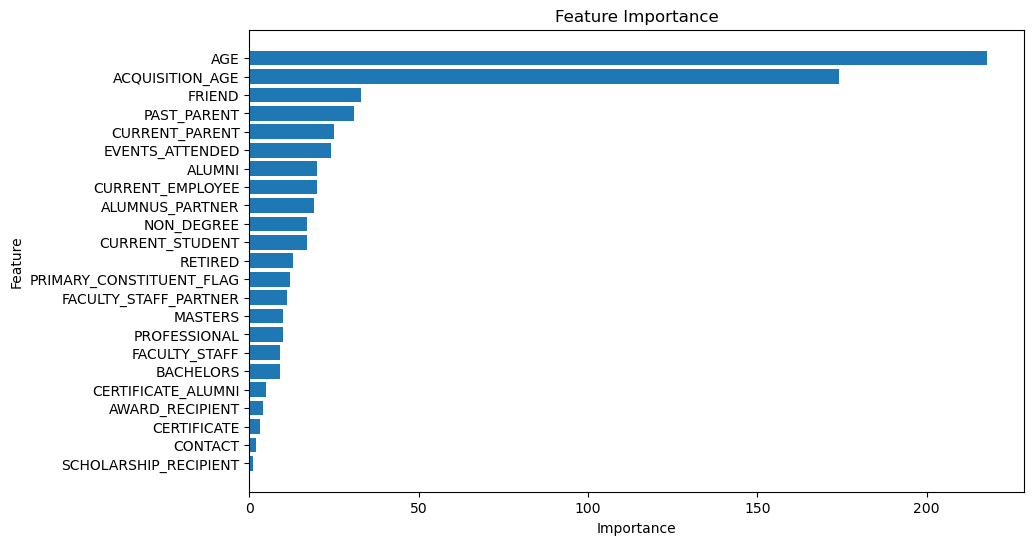

In [26]:
importance_xgb = model_xgb.get_score(importance_type = 'weight')

feature_imp_xgb = pd.DataFrame({
    'Feature':list(importance_xgb.keys()),
    'Importance':list(importance_xgb.values())
})

feature_imp_xgb = feature_imp_xgb.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10,6))
plt.barh(feature_imp_xgb['Feature'], feature_imp_xgb['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance')
plt.gca().invert_yaxis()
plt.show()

#### XGBoost with GridSearch for Best Factors
For gridsearch, xgboost needs a scikit learn wrapper, so I chose classifier with a recall scoring model

In [27]:
# parameters to perform gridsearch and pick the best
param_grid = {
    'max_depth': [3,5,7],
    'learning_rate':[0.01, 0.1, 0.2],
    'n_estimators':[50, 100, 200]
}

model_xgb_best = xgb.XGBClassifier(objective = 'binary:logistic', eval_metric = 'logloss')

grid_search_xgb = GridSearchCV(estimator = model_xgb_best, param_grid = param_grid, cv = 3, scoring = 'recall', verbose=2, n_jobs=-1)
grid_search_xgb.fit(X_train, y_train)

best_params_xgb = grid_search_xgb.best_params_
print(f'Best Parameters: {best_params_xgb}')
print('Best Recall Score: ', grid_search_xgb.best_score_)

Fitting 3 folds for each of 27 candidates, totalling 81 fits
Best Parameters: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 50}
Best Recall Score:  0.9624884764218485


In [28]:
best_model_xgb = xgb.XGBClassifier(**best_params_xgb, ojective='binary:logistic', eval_metric='logloss')
best_model_xgb.fit(X_train, y_train)

train_predictions_xgb_best = best_model_xgb.predict(X_train)
test_predictions_xgb_best = best_model_xgb.predict(X_test)

xgb_best_giving_df = make_results_df(X_train, X_test, encoded_df, 'GIVING_PROBABILITY', 'CONTACT_ID', train_predictions_xgb_best, test_predictions_xgb_best)

C:\Users\perakaml\AppData\Local\anaconda3\Lib\site-packages\xgboost\core.py:158: UserWarning: [23:23:37] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-06abd128ca6c1688d-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "ojective" } are not used.

  warnings.warn(smsg, UserWarning)


Confusion Matrix: 



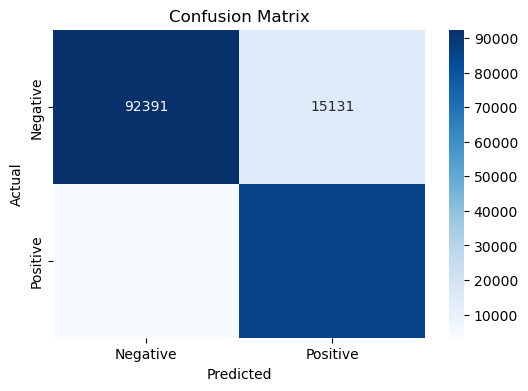

Acuracy Score:  0.90631554889662
Precision:  0.8504679362381287
Recall Score:  0.9629082608841596
F1 Score:  0.9032021074505935


In [29]:
classification_metrics(y_test, test_predictions_xgb_best)

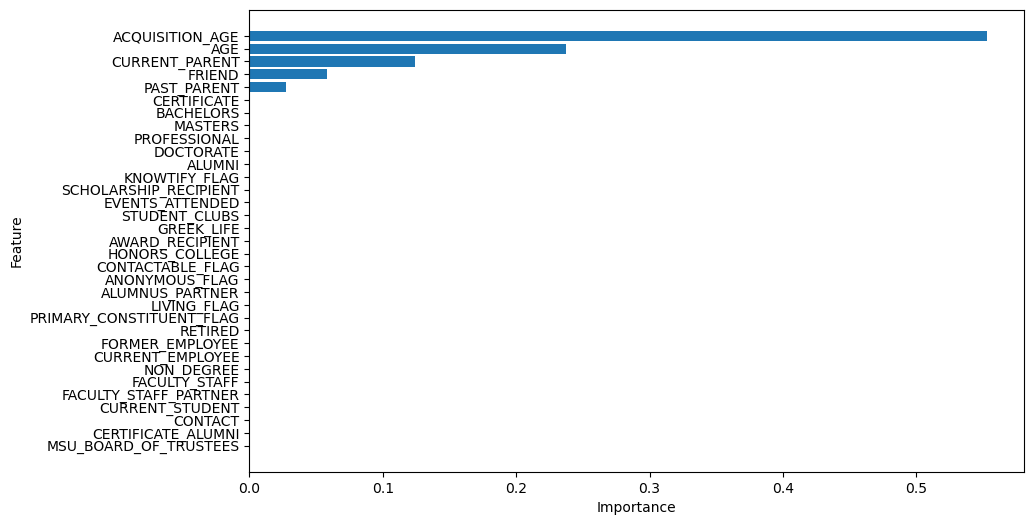

In [30]:
# feature importance
importance_xgb_best = best_model_xgb.feature_importances_

feature_imp_xgb_best = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': importance_xgb_best
    })
feature_imp_xgb_best = feature_imp_xgb_best.sort_values(by = 'Importance', ascending=False)
#print(feature_imp)

plt.figure(figsize=(10,6))
plt.barh(feature_imp_xgb_best['Feature'], feature_imp_xgb_best['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.gca().invert_yaxis()
plt.show()

### Appeal Counts:

In [31]:
master_df = encoded_df.copy()

#### Giving Dict: Importing Responded Appeal Count
Responded Appeal Count: The number of appeals to which the individual has responded.

- Import giving dataframe
- Calculate total giving amount and responded appeal count by adding up each occurance of the individual

In [32]:
from shared_giving import giving_dict

# create new columns amount from the giving dataframe and appeal count responded
master_df['AMOUNT_GIVING_DF'] = 0.0
master_df['APPEAL_COUNT_RESPONDED'] = 0
for index, row in encoded_df.iterrows():
    id = row['CONTACT_ID']
    if id in giving_dict:
        # get the amount and count from dictionary
        amount, count = giving_dict[id]
        # add it to the new columns
        master_df.loc[index, 'AMOUNT_GIVING_DF'] += amount
        master_df.loc[index, 'APPEAL_COUNT_RESPONDED'] += count  

#### Total Appeal Count: Number of Appeals an Individul has Received

- Import appeal count dataframe from sql
- Add every appeal an individual has received

In [33]:
from campaign_count import camp_count_dict

# create a column for total appeal count
master_df['APPEAL_COUNT_TOTAL'] = 0
for index, row in encoded_df.iterrows():
    id = row['CONTACT_ID']
    if id in camp_count_dict:
        count = camp_count_dict[id]
        master_df.loc[index, 'APPEAL_COUNT_TOTAL'] += count

#### Channels Data
The number of appeals an individual has received through each channel: Crowd Funding, Direct Mail, Email, Telemarketing, Web, None

- Import the channel data from sql
- Use one-hot encoder to convert the channel column into their repspetive channel columns.

In [34]:
from channel_data import channel_new_df

master_df = pd.merge(channel_new_df, encoded_df, on = 'CONTACT_ID', how = 'inner')

channels = ['CROWD_FUNDING', 'DIRECT_MAIL', 'EMAIL', 'OTHER', 'TELEMARKETING', 'WEB', 'NONE']

for column in channels:
    data_cast(master_df, column, int, 0)

#### Models with Appeal Count

#### Training and Testing Sets

In [35]:
X_appeal = master_df.drop(['GIFT', 'CONTACT_ID'], axis = 1)  # features
y_appeal = master_df['GIFT']  # target variable

#splitting data
X_appeal_train, X_appeal_test, y_appeal_train, y_appeal_test = train_test_split(X_appeal, y_appeal, test_size = 0.2, random_state = 450)

In [36]:
len(master_df)

1864829

#### Random Forest Regression

In [37]:
model_appeal_rfr = RandomForestRegressor(n_estimators=100, random_state=42)
model_appeal_rfr.fit(X_appeal_train, y_appeal_train)

train_predictions_appeal_rfr = model_appeal_rfr.predict(X_appeal_train)
test_predictions_appeal_rfr = model_appeal_rfr.predict(X_appeal_test)

rfr_appeal_giving_df = make_results_df(X_appeal_train, X_appeal_test, master_df, 'GIVING_PROBABILITY', 'CONTACT_ID', train_predictions_appeal_rfr, test_predictions_appeal_rfr)

In [38]:
regression_metrics(y_appeal_test, test_predictions_appeal_rfr)

Mean Absolute Error:  0.0016279544850088853
Mean Squared Error:  0.0008598874935129567
R-sqaured Score:  0.4223244421924517


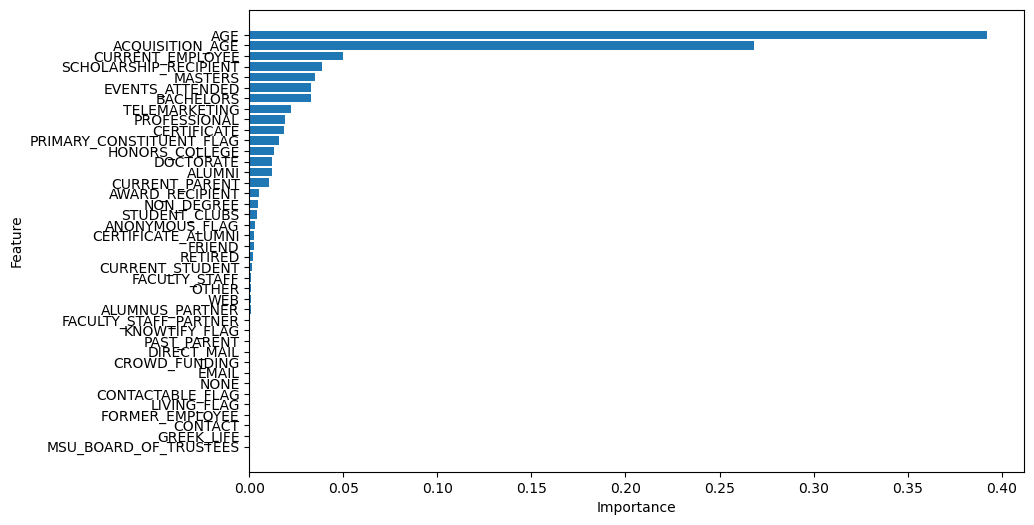

In [39]:
importance_appeal_rfr = model_appeal_rfr.feature_importances_

feature_imp_appeal_rfr = pd.DataFrame({
    'Feature': X_appeal_test.columns,
    'Importance': importance_appeal_rfr
    })
feature_imp_appeal_rfr = feature_imp_appeal_rfr.sort_values(by = 'Importance', ascending=False)
#print(feature_imp)

plt.figure(figsize=(10,6))
plt.barh(feature_imp_appeal_rfr['Feature'], feature_imp_appeal_rfr['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.gca().invert_yaxis()
plt.show()

#### Random Forest Classifier

In [40]:
# rfc - random forest classifier
model_appeal_rfc = RandomForestClassifier(n_estimators = 1000)
model_appeal_rfc.fit(X_appeal_train, y_appeal_train)

# predicted probability values
train_predictions_appeal_rfc = model_appeal_rfc.predict(X_appeal_train)
test_predictions_appeal_rfc = model_appeal_rfc.predict(X_appeal_test)

rfc_appeal_giving_df = make_results_df(X_appeal_train, X_appeal_test, master_df, 'GIVING_PROBABILITY', 'CONTACT_ID', train_predictions_appeal_rfc, test_predictions_appeal_rfc)

Confusion Matrix: 



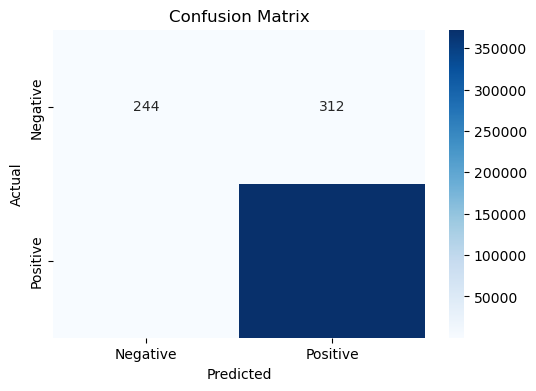

Acuracy Score:  0.9988175865896624
Precision:  0.9991626251700918
Recall Score:  0.9996536075830402
F1 Score:  0.999408056074942


In [41]:
classification_metrics(y_appeal_test, test_predictions_appeal_rfc)

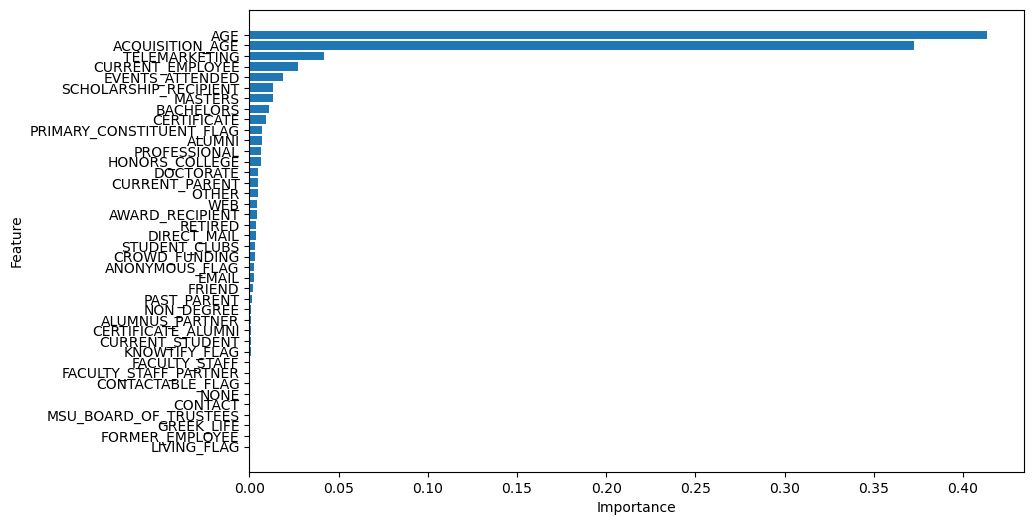

In [42]:
# feature importance
importance_appeal_rfc = model_appeal_rfc.feature_importances_

feature_imp_appeal_rfc = pd.DataFrame({
    'Feature': X_appeal_test.columns,
    'Importance': importance_appeal_rfc
    })
feature_imp_appeal_rfc = feature_imp_appeal_rfc.sort_values(by = 'Importance', ascending=False)
#print(feature_imp)

plt.figure(figsize=(10,6))
plt.barh(feature_imp_appeal_rfc['Feature'], feature_imp_appeal_rfc['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.gca().invert_yaxis()
plt.show()

#### XGBoost

In [43]:
dtrain_appeal = xgb.DMatrix(X_appeal_train, label = y_appeal_train)
dtest_appeal = xgb.DMatrix(X_appeal_test, label = y_appeal_test)

params = {
    'objective':'binary:logistic',
    'max_depth': 3,
    'n_estimators':100,
    'learning_rate':0.1,
    'eval_metric':'logloss'
}

model_appeal_xgb = xgb.train(params, dtrain_appeal, num_boost_round = 100)
train_appeal_predictions_xgb = model_appeal_xgb.predict(dtrain_appeal)
test_appeal_predictions_xgb = model_appeal_xgb.predict(dtest_appeal)

xgb_giving_appeal_df = make_results_df(X_appeal_train, X_appeal_test, master_df, 'GIVING_PROBABILITY', 'CONTACT_ID', train_appeal_predictions_xgb, test_appeal_predictions_xgb)

C:\Users\perakaml\AppData\Local\anaconda3\Lib\site-packages\xgboost\core.py:158: UserWarning: [10:22:06] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-06abd128ca6c1688d-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "n_estimators" } are not used.

  warnings.warn(smsg, UserWarning)


In [44]:
# individuals with 50% or more probability to give
y_pred_appeal_xgb = (test_appeal_predictions_xgb > 0.5).astype(int)

# accuracy
acc_xgb = accuracy_score(y_appeal_test, y_pred_appeal_xgb)
print('Accuracy:', acc_xgb)

# Classification Report
print(classification_report(y_appeal_test, y_pred_appeal_xgb))

Accuracy: 0.9985494656349372
              precision    recall  f1-score   support

           0       0.78      0.04      0.07       556
           1       1.00      1.00      1.00    372410

    accuracy                           1.00    372966
   macro avg       0.89      0.52      0.54    372966
weighted avg       1.00      1.00      1.00    372966



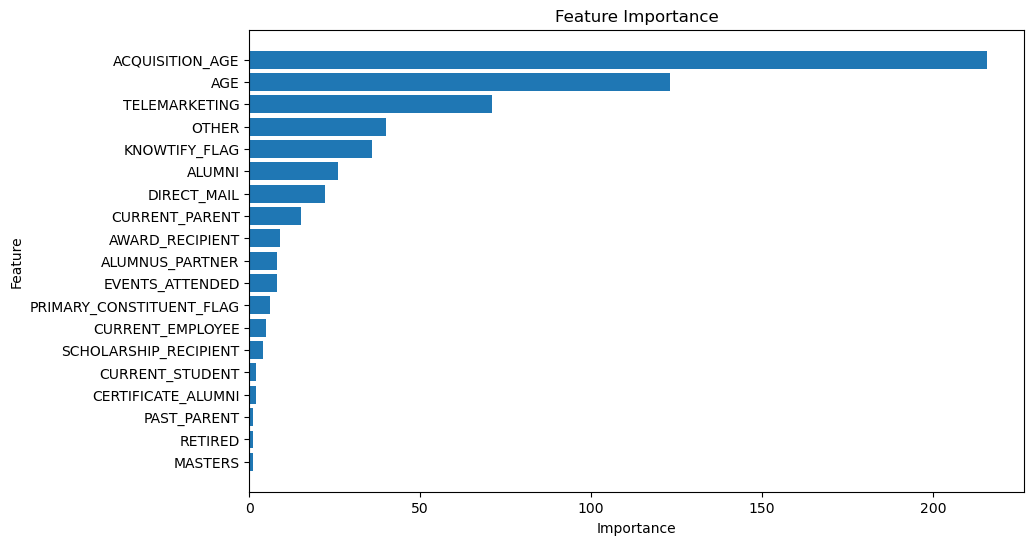

In [45]:
importance_appeal_xgb = model_appeal_xgb.get_score(importance_type = 'weight')

feature_imp_appeal_xgb = pd.DataFrame({
    'Feature':list(importance_appeal_xgb.keys()),
    'Importance':list(importance_appeal_xgb.values())
})

feature_imp_appeal_xgb = feature_imp_appeal_xgb.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10,6))
plt.barh(feature_imp_appeal_xgb['Feature'], feature_imp_appeal_xgb['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance')
plt.gca().invert_yaxis()
plt.show()

#### XGBoost with Grid Search

In [46]:
# parameters to perform gridsearch and pick the best
model_xgb_appeal_best = xgb.XGBClassifier(objective = 'binary:logistic', eval_metric = 'logloss')

grid_search_appeal_xgb = GridSearchCV(estimator = model_xgb_appeal_best, param_grid = param_grid, cv = 3, scoring = 'recall', verbose=2, n_jobs=-1)
grid_search_appeal_xgb.fit(X_train, y_train)

best_params_appeal_xgb = grid_search_appeal_xgb.best_params_
print(f'Best Parameters: {best_params_appeal_xgb}')
print('Best Recall Score: ', grid_search_appeal_xgb.best_score_)

Fitting 3 folds for each of 27 candidates, totalling 81 fits
Best Parameters: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 50}
Best Recall Score:  0.9624884764218485


In [47]:
best_model_appeal_xgb = xgb.XGBClassifier(**best_params_appeal_xgb, ojective='binary:logistic', eval_metric='logloss')
best_model_appeal_xgb.fit(X_appeal_train, y_appeal_train)

train_predictions_xgb_appeal_best = best_model_appeal_xgb.predict(X_appeal_train)
test_predictions_xgb_appeal_best = best_model_appeal_xgb.predict(X_appeal_test)

xgb_appeal_best_giving_df = make_results_df(X_appeal_train, X_appeal_test, master_df, 'GIVING_PROBABILITY', 'CONTACT_ID', 
                                            train_predictions_xgb_appeal_best, test_predictions_xgb_appeal_best)

C:\Users\perakaml\AppData\Local\anaconda3\Lib\site-packages\xgboost\core.py:158: UserWarning: [10:34:14] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-06abd128ca6c1688d-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "ojective" } are not used.

  warnings.warn(smsg, UserWarning)


Confusion Matrix: 



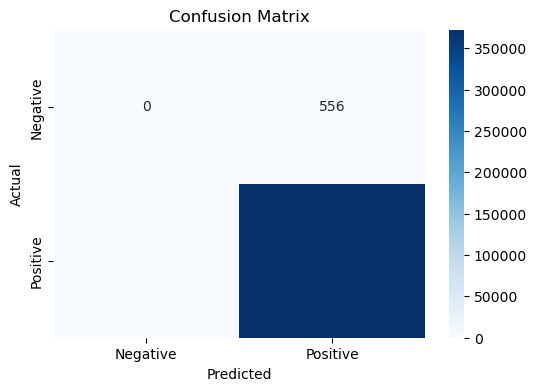

Acuracy Score:  0.9985092474917284
Precision:  0.9985092474917284
Recall Score:  1.0
F1 Score:  0.9992540677456747


In [48]:
classification_metrics(y_appeal_test, test_predictions_xgb_appeal_best)

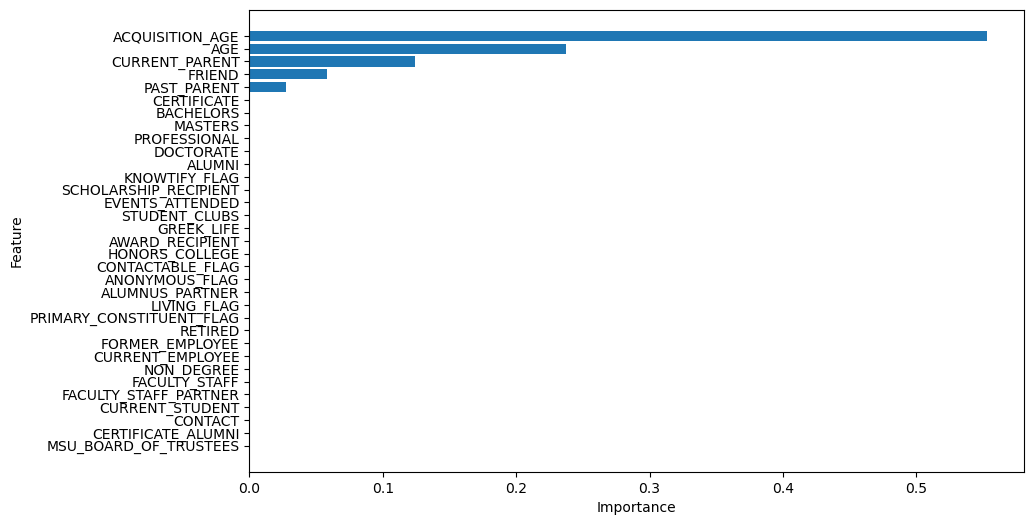

In [49]:
# feature importance
importance_xgb_best = best_model_xgb.feature_importances_

feature_imp_xgb_best = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': importance_xgb_best
    })
feature_imp_xgb_best = feature_imp_xgb_best.sort_values(by = 'Importance', ascending=False)
#print(feature_imp)

plt.figure(figsize=(10,6))
plt.barh(feature_imp_xgb_best['Feature'], feature_imp_xgb_best['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.gca().invert_yaxis()
plt.show()

### Seed Models

In [50]:
# Drop gift and contact id
X_noage = encoded_df.drop(['GIFT', 'CONTACT_ID', 'ACQUISITION_AGE'], axis = 1)  # features
y_noage = encoded_df['GIFT']  # target variable

#splitting data
X_trainn, X_testn, y_trainn, y_testn = train_test_split(X_noage, y_noage, test_size = 0.2, random_state = 450)

#### Random Forest Regressor

In [51]:
# rfr - random forest resgressor
model_rfrn = RandomForestRegressor(n_estimators=100, random_state=42)
model_rfrn.fit(X_trainn, y_trainn)

# predicted probability values
train_predictions_rfrn = model_rfrn.predict(X_trainn)
test_predictions_rfrn = model_rfrn.predict(X_testn)

rfr_giving_dfn = make_results_df(X_trainn, X_testn, encoded_df, 'GIVING_PROBABILITY', 'CONTACT_ID', train_predictions_rfrn, test_predictions_rfrn)

In [52]:
regression_metrics(y_testn, test_predictions_rfrn)

Mean Absolute Error:  0.32559722656756385
Mean Squared Error:  0.16623229314662794
R-sqaured Score:  0.32937289718499096


#### Random Forest Classifier

In [53]:
# rfc - random forest classifier
model_rfcn = RandomForestClassifier(n_estimators = 1000)
model_rfcn.fit(X_trainn, y_trainn)

# predicted probability values
train_predictions_rfcn = model_rfcn.predict(X_trainn)
test_predictions_rfcn = model_rfcn.predict(X_testn)

rfc_giving_dfn = make_results_df(X_trainn, X_testn, encoded_df, 'GIVING_PROBABILITY', 'CONTACT_ID', train_predictions_rfcn, test_predictions_rfcn)

Confusion Matrix: 



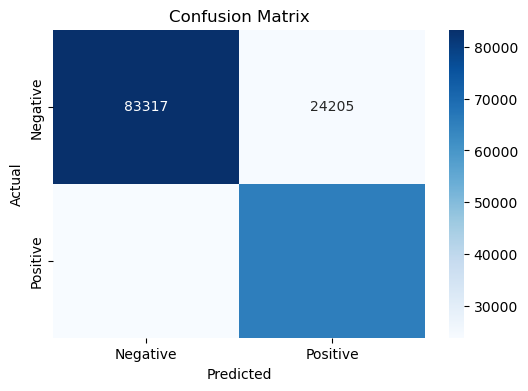

Acuracy Score:  0.7560984280961934
Precision:  0.7303364527629234
Recall Score:  0.7334989314446198
F1 Score:  0.7319142759848828


In [54]:
classification_metrics(y_testn, test_predictions_rfcn)

#### XGBoost

In [55]:
dtrainn = xgb.DMatrix(X_trainn, label = y_trainn)
dtestn = xgb.DMatrix(X_testn, label = y_testn)

params = {
    'objective':'binary:logistic',
    'max_depth': 3,
    'n_estimators':100,
    'learning_rate':0.1,
    'eval_metric':'logloss'
}

model_xgbn = xgb.train(params, dtrainn, num_boost_round = 100)
train_predictions_xgbn = model_xgbn.predict(dtrainn)
test_predictions_xgbn = model_xgbn.predict(dtestn)

xgb_giving_dfn = make_results_df(X_trainn, X_testn, encoded_df, 'GIVING_PROBABILITY', 'CONTACT_ID', train_predictions_xgbn, test_predictions_xgbn)

C:\Users\perakaml\AppData\Local\anaconda3\Lib\site-packages\xgboost\core.py:158: UserWarning: [11:04:25] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-06abd128ca6c1688d-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "n_estimators" } are not used.

  warnings.warn(smsg, UserWarning)


In [56]:
# individuals with 50% or more probability to give
y_pred_xgbn = (test_predictions_xgbn > 0.5).astype(int)

# accuracy
acc_xgbn = accuracy_score(y_testn, y_pred_xgbn)
print('Accuracy:', acc_xgbn)

# Classification Report
print(classification_report(y_testn, y_pred_xgbn))

Accuracy: 0.758104573503644
              precision    recall  f1-score   support

           0       0.78      0.78      0.78    107522
           1       0.74      0.73      0.73     89373

    accuracy                           0.76    196895
   macro avg       0.76      0.76      0.76    196895
weighted avg       0.76      0.76      0.76    196895



#### XGBoost with GridSearch

In [57]:
# parameters to perform gridsearch and pick the best
model_xgb_bestn = xgb.XGBClassifier(objective = 'binary:logistic', eval_metric = 'logloss')

grid_search_xgbn = GridSearchCV(estimator = model_xgb_bestn, param_grid = param_grid, cv = 3, scoring = 'recall', verbose=2, n_jobs=-1)
grid_search_xgbn.fit(X_trainn, y_trainn)

best_params_xgbn = grid_search_xgbn.best_params_
print(f'Best Parameters: {best_params_xgbn}')
print('Best Recall Score: ', grid_search_xgbn.best_score_)

Fitting 3 folds for each of 27 candidates, totalling 81 fits
Best Parameters: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200}
Best Recall Score:  0.7393892013214637


In [58]:
best_model_xgbn = xgb.XGBClassifier(**best_params_xgbn, ojective='binary:logistic', eval_metric='logloss')
best_model_xgbn.fit(X_trainn, y_trainn)

train_predictions_xgb_bestn = best_model_xgbn.predict(X_trainn)
test_predictions_xgb_bestn = best_model_xgbn.predict(X_testn)

xgb_best_giving_dfn = make_results_df(X_trainn, X_testn, encoded_df, 'GIVING_PROBABILITY', 'CONTACT_ID', 
                                            train_predictions_xgb_bestn, test_predictions_xgb_bestn)

C:\Users\perakaml\AppData\Local\anaconda3\Lib\site-packages\xgboost\core.py:158: UserWarning: [11:10:25] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-06abd128ca6c1688d-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "ojective" } are not used.

  warnings.warn(smsg, UserWarning)
